# Multi occlusion shape

In [4]:
cd "/app/"

/app


In [5]:
%run env.py
%run run.py connect

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from vr4mice.analysis.analysis import style
from vr4mice.schema import vr4mice
from vr4mice.analysis import utils, plotting, analysis
from vr4mice.schema.vr4mice import Groups, Labels
from vr4mice.schema.session_metrics import TrialMetrics
from vr4mice.schema.interpolated_trajectories import InterpolatedTrials, MeanXYTrajectory, MeanVelocities
from vr4mice.analysis.stats import get_multi_p_values_binned, get_multi_p_values_global, plot_aperture_heatmap
from statsmodels.stats.anova import AnovaRM
import statsmodels.formula.api as smf
import scipy.stats as stats

style()

save_fig_path = "notebooks/shape_figures/shape_figures/shape_"

In [7]:
BATCH_NAME = "batch1"

trial_df = ((vr4mice.Dataset() & 'session_label = "ar_shape_discrim_multi_occluders"')
            * (vr4mice.DatasetBatch() & {"batch_name": BATCH_NAME}) 
            * TrialMetrics() 
            & vr4mice.ExcludedDataset.exclusion_filter()
            ).fetch(as_dict=True)
trial_df = pd.concat([pd.DataFrame(x) for x in trial_df])
trial_df ["aperture"] = trial_df.aperture.round(2)
trial_df, reward_table = utils.apply_inclusion_criteria(trial_df[["dataset", "aperture", "trial", "trial_left_choice", "trial_rewarded", "trial_tortuosity", "trial_duration"]],
                                                        return_excluded=False,
                                                        )

# Create list of included datasets
sessions_list = trial_df.dataset.unique()
trial_df["mouse_name"] = trial_df.dataset.str.split("_").str [0]

/tmp/ipykernel_113261/2306365698.py:7: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  ).fetch(as_dict=True)


In [8]:
trial_df.mouse_name.nunique(), trial_df.dataset.unique()

(2,
 array(['Vegavis_2024-09-30_1', 'Wiwaxia_2024-10-01_1',
        'Wiwaxia_2024-10-03_1'], dtype=object))

In [9]:
trial_df["lab_id"] = 0
for dataset_name in sessions_list:
    # Fetch lab_id for each dataset
    trial_df.loc[trial_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]

/tmp/ipykernel_113261/3143638681.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  trial_df.loc[trial_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_113261/3143638681.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  trial_df.loc[trial_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_113261/3143638681.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  trial_df.loc[trial_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]


In [10]:
# Linear Mixed Model (with Mouse)
lmm_model = smf.mixedlm("trial_rewarded ~ C(aperture)", 
                        data=trial_df, groups=trial_df["mouse_name"]).fit(method='bfgs')

# Ordinary Least Squares (without Mouse)
ols_model = smf.ols("trial_rewarded ~ C(aperture)", data=trial_df).fit()

# Likelihood Ratio Test
lr_stat = 2 * (lmm_model.llf - ols_model.llf)
p_val = stats.chi2.sf(lr_stat, df=1) # 1 degree of freedom for the random effect

print(f"LRT Statistic: {lr_stat:.4f}")
print(f"P-value for Mouse effect: {p_val:.4f}")

if p_val > 0.05:
    print("Justification: Mouse identity does not significantly improve the model. Independent ANOVA is valid.")
else:
    print("Caution: Mouse identity explains significant variance.")

LRT Statistic: -26.1087
P-value for Mouse effect: 1.0000
Justification: Mouse identity does not significantly improve the model. Independent ANOVA is valid.


/opt/conda/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/conda/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/opt/conda/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 1.733900
  warnings.warn(msg, ConvergenceWarning)
/opt/conda/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


                Anova
         F Value Num DF Den DF Pr > F
-------------------------------------
aperture  1.9194 4.0000 8.0000 0.2006



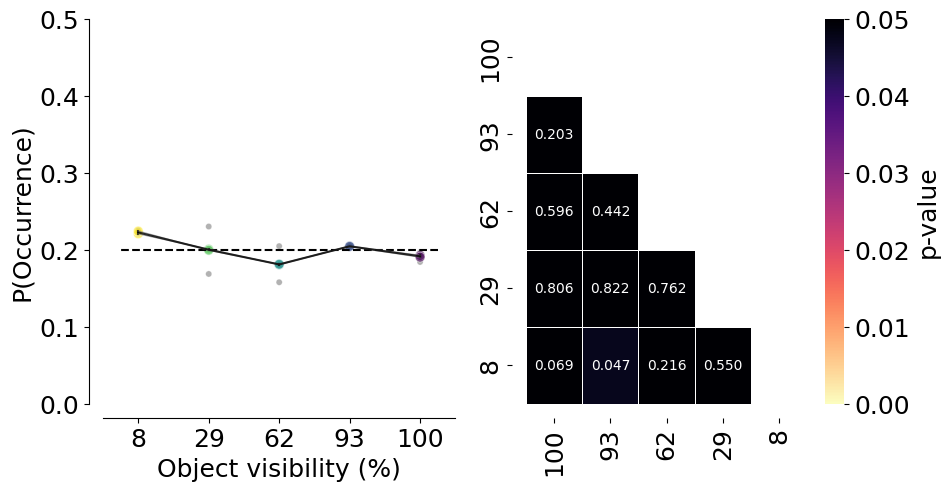

In [11]:
# Occurance of the different conditions
counts = (
    trial_df.groupby(["dataset", "mouse_name", "aperture"])
    .trial.nunique()
    .reset_index(name="trial_count")
)
total_trials = (
    trial_df.groupby("dataset").trial.nunique().reset_index(name="total_trials")
)

counts = counts.merge(total_trials, on="dataset")
counts["probability"] = counts["trial_count"] / counts["total_trials"]
counts["aperture"] = counts["aperture"].astype("float")
counts = counts.sort_values("aperture")

counts["aperture_numeric"] = counts["aperture"]
aperture_order = counts["aperture"].unique()
counts["aperture"] = pd.Categorical(counts["aperture"].astype("str"), categories=aperture_order.astype("str"), ordered=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.lineplot(
    data=counts.groupby(["aperture", "mouse_name"], as_index=False).probability.mean(),
    x="aperture",
    y="probability",
    units="mouse_name",
    estimator=None,
    color="grey",
    alpha=0.7,
    linewidth=1,
    zorder=3,
    ax=ax[0]
)

sns.scatterplot(
    data=counts.groupby(["aperture", "mouse_name"], as_index=False).probability.mean(),
    x="aperture",
    y="probability",
    hue="aperture",
    palette=plotting.colors_multi_aperture[::-1],
    alpha=0.6,
    s=50,
    zorder=2,
    ax=ax[0]
)

sns.scatterplot(
    data=counts,
    x="aperture",
    y="probability",
    hue="aperture",
    palette=["grey"] * counts["dataset"].nunique(),
    alpha=0.6,
    zorder=1,
    s=20,
    ax=ax[0]
)

sns.lineplot(
    data=counts.groupby(["aperture", "mouse_name"], as_index=False).probability.mean(),
    x="aperture",
    y="probability",
    color="black",
    err_style="bars",
    errorbar="se",
    alpha=0.8,
    zorder=4,
    ax=ax[0]
)

ax[0].hlines(
    0.2,
    xmin=-0.25,
    xmax=len(trial_df.aperture.unique()) - 0.75,
    linestyles="dashed",
    colors="k",
)

ax[0].set_ylim(0, .5)
ax[0].set_xlim(-0.5, 4.5)
ax[0].invert_xaxis()

ax[0].set_xticks([4, 3, 2, 1, 0], ["8", "29", "62", "93", "100"])

ax[0].set_xlabel("Object visibility (%)")
ax[0].set_ylabel("P(Occurrence)")
sns.despine(offset=10)
ax[0].legend([], [], frameon=False)

# Use numeric aperture for statistical analysis
counts_for_stats = counts.copy()
counts_for_stats['aperture'] = counts_for_stats['aperture_numeric']
p_values = get_multi_p_values_global(counts_for_stats,  y_var="probability")
plot_aperture_heatmap(p_values, ax= ax[1])
ax[1].set_xticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])
ax[1].set_yticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])

print(AnovaRM(counts_for_stats, depvar="probability", subject="dataset", within=["aperture"]).fit())

plt.savefig(save_fig_path + "figure5_occurance.svg", transparent=True)

4.0-5.57: TtestResult(statistic=1.383928793755609, pvalue=0.3005873190118711, df=2)
4.0-7.75: TtestResult(statistic=-1.2193868339603111, pvalue=0.34698750617384544, df=2)
4.0: mean=0.570 ± 0.022
5.57-7.75: TtestResult(statistic=-1.646172101047026, pvalue=0.24147448016918122, df=2)
5.57: mean=0.520 ± 0.045
7.75: mean=0.649 ± 0.042
10.78-4.0: TtestResult(statistic=3.186603370758348, pvalue=0.08596986260084472, df=2)
10.78-5.57: TtestResult(statistic=5.278021812499415, pvalue=0.03407288717110048, df=2)
10.78-7.75: TtestResult(statistic=0.17610596396745257, pvalue=0.8764286819193292, df=2)
10.78-15.0: TtestResult(statistic=-1.0839175627572812, pvalue=0.39167903859403463, df=2)
10.78: mean=0.665 ± 0.050
15.0-4.0: TtestResult(statistic=6.661690256167175, pvalue=0.021799502195735853, df=2)
15.0-5.57: TtestResult(statistic=4.900716135206967, pvalue=0.0392048911759492, df=2)
15.0-7.75: TtestResult(statistic=1.5343322290904355, pvalue=0.2646968131318449, df=2)
15.0: mean=0.716 ± 0.006
          

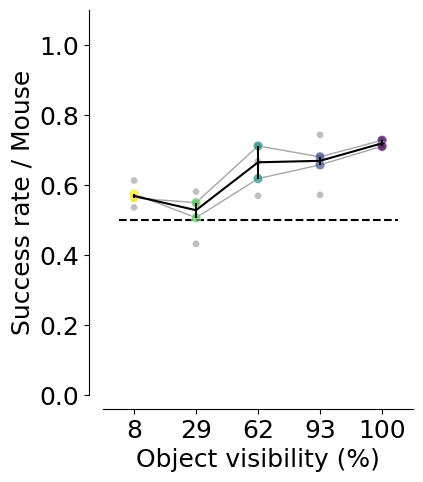

In [12]:
# Success rate per mouse
fig, ax = plt.subplots(1, 1, figsize=(4, 5))
plotting.plot_rate(
    df=trial_df,
    label_x="trial_rewarded",
    per_aperture=True,
    ax=ax,
    cmap=plotting.colors_multi_aperture,
    per_mouse=True,
)
ax.hlines(
    0.5,
    xmin=-0.25,
    xmax=len(trial_df.aperture.unique()) - 0.75,
    linestyles="dashed",
    colors="k",
)

ax.set_ylim(0, 1.1)
ax.set_xlim(-0.5, 4.5)
ax.set_xlabel("Object visibility (%)")
ax.set_ylabel("Success rate / Mouse")
ax.set_xticks([0, 1, 2, 3, 4], ["8", "29", "62", "93", "100"])

ax.legend([], [], frameon=False)
sns.despine(offset=10)

print(AnovaRM(counts_for_stats, depvar="probability", subject="dataset", within=["aperture"]).fit())

plt.savefig(save_fig_path + "figure5_rewards_per_mouse.svg", transparent=True)

4.0-5.57: TtestResult(statistic=0.7360636608302422, pvalue=0.538315208587886, df=2)
4.0-7.75: TtestResult(statistic=-1.2820667479452517, pvalue=0.32835525785420583, df=2)
4.0: mean=0.570 ± 0.022
5.57-7.75: TtestResult(statistic=-5.735695109342565, pvalue=0.02907752559712033, df=2)
5.57: mean=0.520 ± 0.045
7.75: mean=0.649 ± 0.042
10.78-4.0: TtestResult(statistic=1.3051485152068265, pvalue=0.3217982891789991, df=2)
10.78-5.57: TtestResult(statistic=15.569444300587723, pvalue=0.004099930580639804, df=2)
10.78-7.75: TtestResult(statistic=0.504009751314869, pvalue=0.6642936974136642, df=2)
10.78-15.0: TtestResult(statistic=-0.9827577746005339, pvalue=0.4293436983976535, df=2)
10.78: mean=0.665 ± 0.050
15.0-4.0: TtestResult(statistic=6.661690256167175, pvalue=0.021799502195735853, df=2)
15.0-5.57: TtestResult(statistic=4.219596808096687, pvalue=0.051835781105828545, df=2)
15.0-7.75: TtestResult(statistic=1.6802365974439344, pvalue=0.23492673070197864, df=2)
15.0: mean=0.716 ± 0.006
        

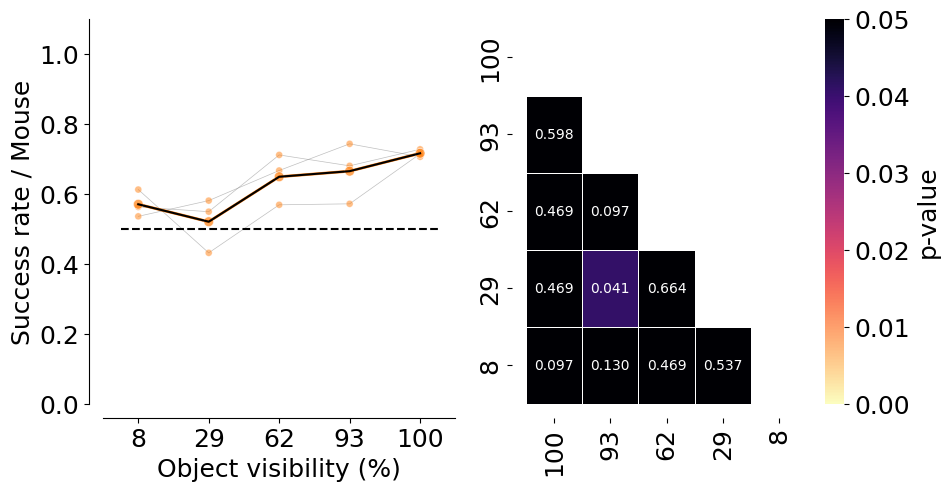

In [13]:
# Success rate per mouse
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plotting.plot_rate(
    df=trial_df,
    label_x="trial_rewarded",
    per_aperture=True,
    ax=ax[0],
    cmap=plotting.colors_multi_aperture,
    per_lab=True,
)
ax[0].hlines(
    0.5,
    xmin=-0.25,
    xmax=len(trial_df.aperture.unique()) - 0.75,
    linestyles="dashed",
    colors="k",
)

ax[0].set_ylim(0, 1.1)
ax[0].set_xlim(-0.5, 4.5)
ax[0].set_xlabel("Object visibility (%)")
ax[0].set_ylabel("Success rate / Mouse")
ax[0].set_xticks([0, 1, 2, 3, 4], ["8", "29", "62", "93", "100"])

ax[0].legend([], [], frameon=False)
sns.despine(offset=10)

p_values = get_multi_p_values_global(trial_df, y_var="trial_rewarded")
plot_aperture_heatmap(p_values, ax=ax[1])
ax[1].set_xticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])
ax[1].set_yticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])

mean_mouse = trial_df.groupby(["dataset", "aperture"], as_index=False).mean(numeric_only=True)
print(AnovaRM(mean_mouse, depvar="trial_rewarded", subject="dataset", within=["aperture"]).fit())

plt.savefig(save_fig_path + "figure5_rewards.svg", transparent=True)

4.0-5.57: TtestResult(statistic=-0.9941682168765836, pvalue=0.42490093881135393, df=2)
4.0-7.75: TtestResult(statistic=-1.1275709255487052, pvalue=0.3765868345944122, df=2)
4.0: mean=0.632 ± 0.246
5.57-7.75: TtestResult(statistic=0.6719524613378555, pvalue=0.5708384363413164, df=2)
5.57: mean=0.879 ± 0.004
7.75: mean=0.829 ± 0.071
10.78-4.0: TtestResult(statistic=-0.4845001432211057, pvalue=0.6758990002464391, df=2)
10.78-5.57: TtestResult(statistic=-2.3106612281484504, pvalue=0.14707029870379437, df=2)
10.78-7.75: TtestResult(statistic=-1.6771711885900864, pvalue=0.23550644243580413, df=2)
10.78-15.0: TtestResult(statistic=0.4928262564546973, pvalue=0.6709279175811835, df=2)
10.78: mean=0.451 ± 0.184
15.0-4.0: TtestResult(statistic=-1.9207801182668753, pvalue=0.19472436275461041, df=2)
15.0-5.57: TtestResult(statistic=-5.157769145963248, pvalue=0.03559539396390055, df=2)
15.0-7.75: TtestResult(statistic=-7.454266782043494, pvalue=0.01752489792362718, df=2)
15.0: mean=0.309 ± 0.110
4.0

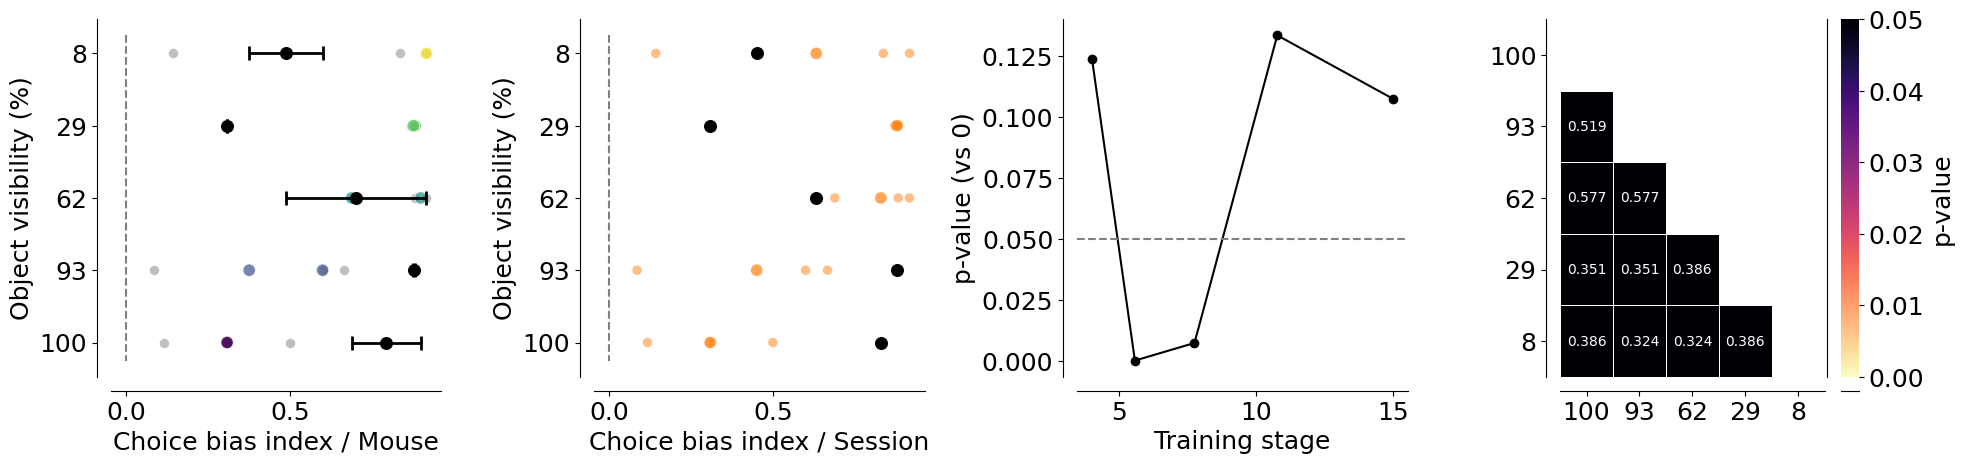

In [14]:
trial_df["trial_bias"] = 2 * trial_df["trial_left_choice"] - 1 

# Choice bias per mouse and per lab
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
plotting.plot_rate(
    df=trial_df,
    label_x="trial_left_choice",
    plot_bias=True,
    per_aperture=True,
    ax=ax[0],
    cmap=plotting.colors_multi_aperture,
    per_mouse=True,
)
ax[0].vlines(
    0,
    ymin=-0.25,
    ymax=len(trial_df.aperture.unique()) - 0.75,
    linestyles="dashed",
    colors="grey",
)

ax[0].set_ylabel("Object visibility (%)")
ax[0].set_xlabel("Choice bias index / Mouse")
ax[0].set_yticks([0, 1, 2, 3, 4], ["8", "29", "62", "93", "100"])

ax[0].legend([], [], frameon=False)
sns.despine(offset=10)

plotting.plot_rate(
    df=trial_df,
    label_x="trial_left_choice",
    per_aperture=True,
    plot_bias=True,
    ax=ax[1],
    cmap=plotting.colors_multi_aperture,
    per_lab=True,
)
ax[1].vlines(
    0,
    ymin=-0.25,
    ymax=len(trial_df.aperture.unique()) - 0.75,
    linestyles="dashed",
    colors="grey",
)

ax[1].set_ylabel("Object visibility (%)")
ax[1].set_xlabel("Choice bias index / Session")
ax[1].set_yticks([0, 1, 2, 3, 4], ["8", "29", "62", "93", "100"])

ax[1].legend([], [], frameon=False)

# One-sample t-test of bias against 0 (null) across session
apertures_ = []
for stage in sorted(trial_df.aperture.unique()):
    #vals = trial_df.groupby("dataset").mean().loc[trial_df.aperture == stage, "trial_bias"]
    vals = trial_df[trial_df.aperture == stage].groupby("dataset")["trial_bias"].mean()
    t_stat, p_val = stats.ttest_1samp(vals, 0)
    apertures_.append({
        "aperture": stage,
        "n": len(vals),
        "mean_bias": vals.mean(),
        "t_stat": t_stat,
        "df": max(len(vals) - 1, 0),
        "p_value": p_val,
    })
apertures_df = pd.DataFrame(apertures_)
print("One-sample t-tests vs 0 (bias)")
print(apertures_df)

# Plot p-values only (no bar/box)
ax[2].plot(apertures_df["aperture"], apertures_df["p_value"], 
           marker="o", linestyle="-", color="k")
ax[2].axhline(0.05, color="grey", linestyle="--")
ax[2].set_xlabel("Training stage")
ax[2].set_ylabel("p-value (vs 0)")

# Plot p-values of the multi-comparison test
p_values = get_multi_p_values_global(trial_df, y_var="trial_bias")
plot_aperture_heatmap(p_values, ax=ax[3])
ax[3].set_xticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])
ax[3].set_yticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])

mean_mouse = trial_df.groupby(["dataset", "aperture"], as_index=False).mean(numeric_only=True)
print(AnovaRM(mean_mouse, depvar="trial_bias", subject="dataset", within=["aperture"]).fit())

sns.despine(offset=10)
plt.tight_layout(pad=2)

plt.savefig(save_fig_path + "figure5_choice_bias.svg", transparent=True)

                Anova
         F Value Num DF Den DF Pr > F
-------------------------------------
aperture  2.0307 4.0000 8.0000 0.1828



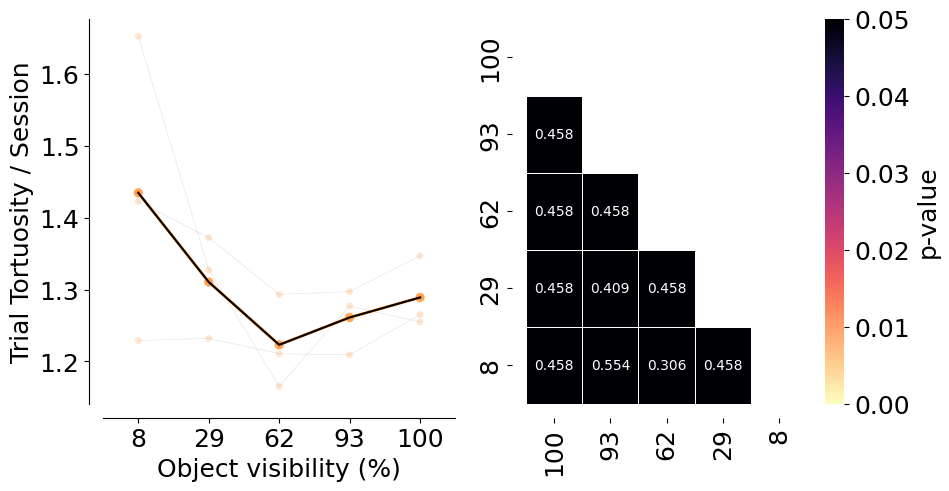

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

counts = (
    trial_df
    .groupby(["lab_id", "dataset", "aperture"], as_index=False)
    .trial_tortuosity.mean()
)

counts["count"] = counts["trial_tortuosity"]
counts = pd.DataFrame(counts.reset_index())
counts.aperture = counts.aperture.round(2).astype(str)

plotting._plot_bar_counts(
    counts=counts,
    label_x="aperture",
    alpha=0.2,
    ax=ax[0],
    per_lab=True,
    cmap=plotting.colors_aperture[0:2],
)
ax[0].invert_xaxis()

ax[0].set_xlim(-0.5, 4.5)
ax[0].set_xlabel("Object visibility (%)")
ax[0].set_ylabel("Trial Tortuosity / Session")
ax[0].set_xticks([0, 1, 2, 3, 4], ["8", "29", "62", "93", "100"])

ax[0].legend([], [], frameon=False)
sns.despine(offset=10)

p_values = get_multi_p_values_global(trial_df,  y_var="trial_tortuosity")
plot_aperture_heatmap(p_values, ax=ax[1])
ax[1].set_xticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])
ax[1].set_yticks([4.5, 3.5, 2.5, 1.5, 0.5], ["8", "29", "62", "93", "100"])

mean_mouse = trial_df.groupby(["dataset", "aperture"], as_index=False).mean(numeric_only=True)
print(AnovaRM(mean_mouse, depvar="trial_tortuosity", subject="dataset", within=["aperture"]).fit())

plt.savefig(save_fig_path + "figure5_tortuosity.svg", transparent=True)

## Trajectory analysis

In [16]:
xy_df = []
for m in sessions_list:
    xy_df.append(pd.DataFrame((MeanXYTrajectory() & f'dataset="{m}"').fetch(as_dict=True)[0]))
xy_df = pd.concat(xy_df)
xy_df["mouse_name"] = xy_df.dataset.str.split("_").str [0]

/tmp/ipykernel_113261/1758988696.py:3: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  xy_df.append(pd.DataFrame((MeanXYTrajectory() & f'dataset="{m}"').fetch(as_dict=True)[0]))
/tmp/ipykernel_113261/1758988696.py:3: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  xy_df.append(pd.DataFrame((MeanXYTrajectory() & f'dataset="{m}"').fetch(as_dict=True)[0]))
/tmp/ipykernel_113261/1758988696.py:3: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  xy_df.append(pd.DataFrame((MeanXYTrajectory() & f'dataset="{m}"').fetch(as_dict=True)[0]))


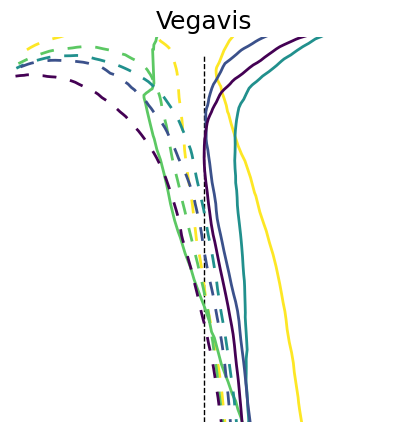

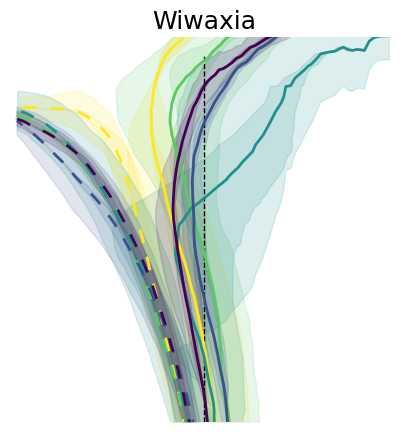

In [17]:
# Mean and error by mouse
mean_mouse = analysis.mean_xy_trajectory(xy_df,
                                         index_columns=[
                                             "mouse_name", "aperture", "trial_left_choice", "trial_length"
                                         ])

for m in mean_mouse.mouse_name.unique():
    plotting.plot_mean_xy_trajectory(mean_mouse[mean_mouse.mouse_name == m], cmap=plt.cm.viridis_r, color_by="aperture", style_by="choice")
    plt.title(m)
    plt.savefig(save_fig_path + f"figure5_trajectories_time_{m}.svg", transparent=True)
    plt.savefig(save_fig_path + f"figure5_trajectories_time_{m}.png", transparent=True, dpi=300)

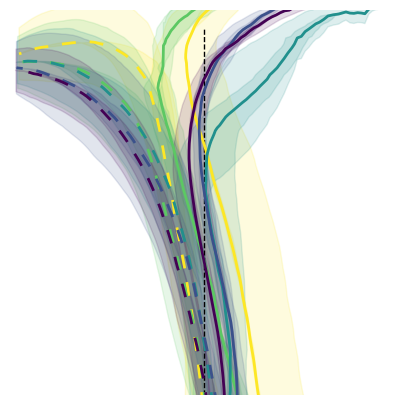

In [18]:
# Mean and error by aperture and choice
mean_group = analysis.mean_xy_trajectory(mean_mouse, 
                                         index_columns=[
                                             "aperture",  "trial_left_choice", "trial_length"
                                         ])

# Plot the mean trajectories from 0, 23 cm in y axis, -18, 18 cm in x axis, colored by choice and styled by aperture
plotting.plot_mean_xy_trajectory(mean_group, cmap=plt.cm.viridis_r, color_by="aperture", style_by="choice")

plt.savefig(save_fig_path + "figure5_trajectories_time.svg", transparent=True)
plt.savefig(save_fig_path + "figure5_trajectories_time.png", transparent=True, dpi=300)

## Stats on trajectories

In [19]:
y_binned_df = []
for m in sessions_list:
    try:
        y_binned_df.append(pd.DataFrame((InterpolatedTrials() & f'dataset="{m}"').fetch("dataset", "aperture", "trial", "trial_left_choice", "x", "y", "flip_one_side", "trial_rewarded", "velocity", "trial_length", as_dict=True)[0]))
    except Exception as err:
        print(err)
y_binned_df = pd.concat(y_binned_df)

/tmp/ipykernel_113261/972093021.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  y_binned_df.append(pd.DataFrame((InterpolatedTrials() & f'dataset="{m}"').fetch("dataset", "aperture", "trial", "trial_left_choice", "x", "y", "flip_one_side", "trial_rewarded", "velocity", "trial_length", as_dict=True)[0]))
/tmp/ipykernel_113261/972093021.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  y_binned_df.append(pd.DataFrame((InterpolatedTrials() & f'dataset="{m}"').fetch("dataset", "aperture", "trial", "trial_left_choice", "x", "y", "flip_one_side", "trial_rewarded", "velocity", "trial_length", as_dict=True)[0]))
/tmp/ipykernel_113261/972093021.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  y_binned_df.append(pd.DataFrame((InterpolatedTrials() & f'dataset="

In [20]:
aperture_to_occlusion = {
    15.0: 100,  # Saturated (exceeds original 12.0 maximum)
    10.78: 93,
    7.75: 62,
    5.57: 29,
    4.0: 8,
}

y_binned_df["aperture"] = y_binned_df["aperture"].map(aperture_to_occlusion)
y_binned_df["mouse_name"] = y_binned_df.dataset.str.split("_").str [0]
y_binned_df["x_flipped"] = y_binned_df.x * y_binned_df.flip_one_side
data = utils.create_bins(y_binned_df)
y_binned_df_mean = analysis.mean_xy_trajectory(data, index_columns= ["dataset", "mouse_name", "aperture", "bin_centers"], values=["x_flipped", "y"])

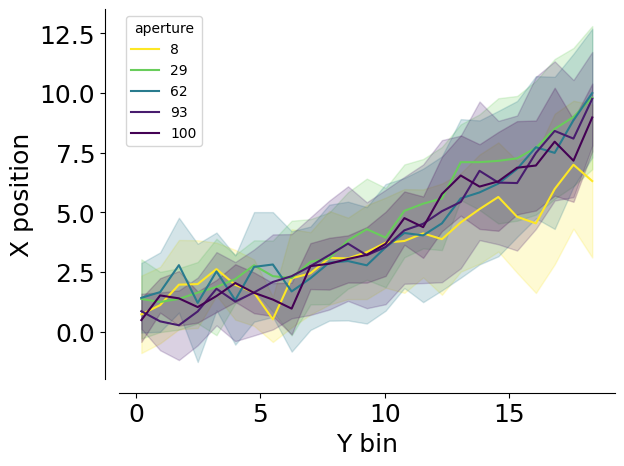

In [21]:
# NOTE(celia): Data unbalanced across bins, so only include bins so that balanced
stats_binned = y_binned_df_mean[(y_binned_df_mean.bin_centers >= 0) & (y_binned_df_mean.bin_centers <= 19)]

sns.lineplot(data=stats_binned, x="bin_centers", y="x_flipped", hue="aperture", palette= "viridis_r",errorbar="se")
plt.xlabel("Y bin")
plt.ylabel("X position")

sns.despine(offset=10)
plt.savefig(save_fig_path + "figure5_mean_xy_trajectory.svg")


In [22]:
print(
    AnovaRM(
        data=stats_binned,
        depvar="x_flipped",
        subject="dataset",
        within=["aperture", "bin_centers"],
    ).fit()
)

                       Anova
                     F Value  Num DF  Den DF  Pr > F
----------------------------------------------------
aperture              0.4303  4.0000   8.0000 0.7834
bin_centers          24.3413 24.0000  48.0000 0.0000
aperture:bin_centers  1.6022 96.0000 192.0000 0.0031



In [23]:
p_value_df = get_multi_p_values_binned(stats_binned, x_var="bin_centers", y_var="x_flipped")

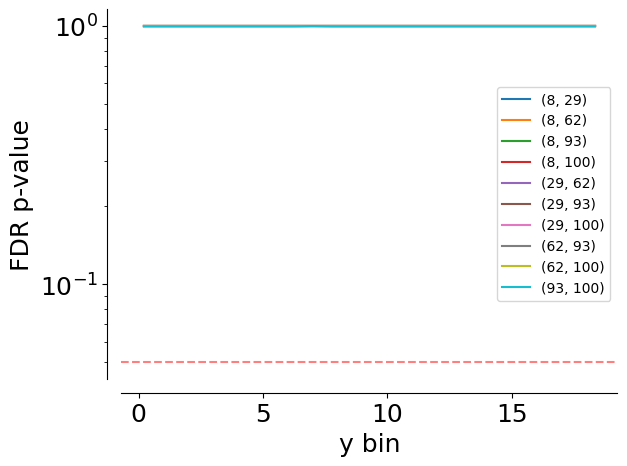

In [24]:
sns.lineplot(data = p_value_df, x="bin", y="p_value_corr", hue=zip(p_value_df.comp1, p_value_df.comp2))
plt.ylabel("FDR p-value")
plt.xlabel("y bin")
plt.yscale("log")
plt.axhline(0.05, linestyle="dashed", color="red", alpha=0.5)

sns.despine(offset=10)
plt.savefig(save_fig_path + "figure5_pos_pvalue.svg", transparent=True)

In [25]:
p_value_df.pivot(index = "bin", columns=["comp1", "comp2"], values=["p_value_corr"])

p_value_corr                                                    \
comp1             8                                       29             
comp2            29        62        93        100       62        93    
bin                                                                      
0.2145      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
0.9695      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
1.7245      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
2.4795      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
3.2345      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
3.9895      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
4.7445      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
5.5000      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
6.2555      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
7.0105      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
7.7655      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
8.5205      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
9.2755      0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
10.0305     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
10.7855     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
11.5405     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
12.2955     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
13.0510     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
13.8065     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
14.5615     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
15.3165     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
16.0715     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
16.8265     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
17.5815     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   
18.3365     0.995998  0.995998  0.995998  0.995998  0.995998  0.995998   

                                                 
comp1                    62                  93  
comp2         100       93        100       100  
bin                                              
0.2145   0.995998  0.995998  0.995998  0.995998  
0.9695   0.995998  0.995998  0.995998  0.995998  
1.7245   0.995998  0.995998  0.995998  0.995998  
2.4795   0.995998  0.995998  0.995998  0.995998  
3.2345   0.995998  0.995998  0.995998  0.995998  
3.9895   0.995998  0.995998  0.995998  0.995998  
4.7445   0.995998  0.995998  0.995998  0.995998  
5.5000   0.995998  0.995998  0.995998  0.995998  
6.2555   0.995998  0.995998  0.995998  0.995998  
7.0105   0.995998  0.995998  0.995998  0.998791  
7.7655   0.995998  0.995998  0.995998  0.995998  
8.5205   0.995998  0.995998  0.995998  0.995998  
9.2755   0.995998  0.995998  0.995998  0.995998  
10.0305  0.995998  0.995998  0.995998  0.995998  
10.7855  0.995998  0.995998  0.995998  0.995998  
11.5405  0.995998  0.995998  0.995998  0.995998  
12.2955  0.995998  0.995998  0.995998  0.995998  
13.0510  0.995998  0.995998  0.995998  0.995998  
13.8065  0.995998  0.995998  0.995998  0.995998  
14.5615  0.995998  0.995998  0.995998  0.995998  
15.3165  0.995998  0.995998  0.995998  0.995998  
16.0715  0.995998  0.995998  0.995998  0.995998  
16.8265  0.995998  0.995998  0.995998  0.995998  
17.5815  0.995998  0.995998  0.995998  0.995998  
18.3365  0.995998  0.995998  0.995998  0.995998

## Velocity analysis

In [26]:
velocity_df = []
for m in sessions_list:
    #print(m)
    velocity_df.append(pd.DataFrame((MeanVelocities() & f'dataset="{m}"').fetch(as_dict=True)[0]))
velocity_df = pd.concat(velocity_df)

mean_mouse = velocity_df.groupby(["dataset", "aperture", "trial_length"],as_index=False).mean()

/tmp/ipykernel_113261/1590699916.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  velocity_df.append(pd.DataFrame((MeanVelocities() & f'dataset="{m}"').fetch(as_dict=True)[0]))
/tmp/ipykernel_113261/1590699916.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  velocity_df.append(pd.DataFrame((MeanVelocities() & f'dataset="{m}"').fetch(as_dict=True)[0]))
/tmp/ipykernel_113261/1590699916.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  velocity_df.append(pd.DataFrame((MeanVelocities() & f'dataset="{m}"').fetch(as_dict=True)[0]))


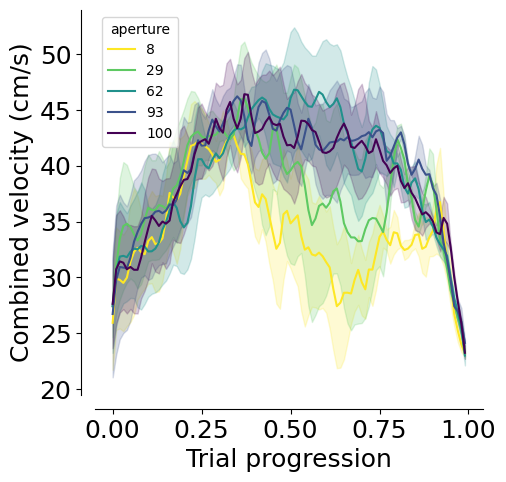

In [27]:
# Map the values
mean_mouse['aperture'] = mean_mouse['aperture'].map(aperture_to_occlusion)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.lineplot(
    data=mean_mouse,
    x="trial_length",
    y="velocity",
    palette=plotting.colors_multi_aperture,
    hue="aperture",
    errorbar="se",
    ax=ax,
)

sns.despine(offset=10)
ax.set_xlabel("Trial progression")
ax.set_ylabel("Combined velocity (cm/s)")
plt.savefig(save_fig_path + "figure5_velocity.svg", transparent=True)

In [28]:
print(
    AnovaRM(
        data=mean_mouse,
        depvar="velocity",
        subject="dataset",
        within=["aperture", "trial_length"],
    ).fit()
)

                        Anova
                      F Value  Num DF   Den DF  Pr > F
------------------------------------------------------
aperture               9.8328   4.0000   8.0000 0.0035
trial_length           1.5274  99.0000 198.0000 0.0062
aperture:trial_length  2.5419 396.0000 792.0000 0.0000



In [29]:
p_value_df = get_multi_p_values_binned(mean_mouse, x_var="trial_length", y_var="velocity")

In [30]:
p_value_df

,bin,comp1,comp2,p_value,p_value_corr
0,0.00,8,29,0.445647,0.768093
0,0.00,8,62,0.589918,0.838484
0,0.00,8,93,0.758621,0.909618
0,0.00,8,100,0.347831,0.715701
0,0.00,29,62,0.988154,0.993946
...,...,...,...,...,...
0,0.99,29,93,0.498440,0.781721
0,0.99,29,100,0.779081,0.910142
0,0.99,62,93,0.415044,0.754732
0,0.99,62,100,0.564533,0.824136


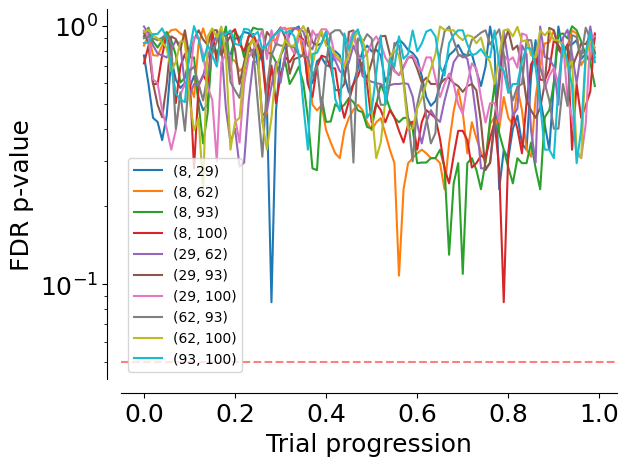

In [31]:
sns.lineplot(data = p_value_df, x="bin", y="p_value_corr", hue=zip(p_value_df.comp1, p_value_df.comp2))
plt.ylabel("FDR p-value")
plt.xlabel("Trial progression")
plt.axhline(0.05, linestyle="dashed", color="red", alpha=0.5)
plt.yscale("log")

sns.despine(offset=10)
plt.savefig(save_fig_path + "figure5_velocity_pvalue.svg", transparent=True)